# ЛАБОРАТОРНА РОБОТА № 4

## Візуальний аналіз даних та часові ряди — аналіз у двох середовищах

**Курс:** СК26 «Інтелектуальний аналіз та візуалізація даних»
**Кафедра систем штучного інтелекту, Національний університет «Львівська політехніка»**
**Оцінювання:** 4 бали

---

## Визначення варіанта

Заповніть три поля в клітинці нижче й виконайте обидві службові клітинки —
номер варіанта, ринок і товар визначаться автоматично.

In [ ]:
SURNAME_NAME = 'Лящук Соломія'   
GROUP        = 'ШІ-33'             
NUMBER       = 6                    

assert SURNAME_NAME.strip(), 'Впишіть прізвище та ім\'я'
assert GROUP.strip(),        'Впишіть групу'
assert isinstance(NUMBER, int) and 1 <= NUMBER <= 30, 'Номер має бути цілим від 1 до 30'
print('Дані прийнято:', SURNAME_NAME, '|', GROUP, '| номер', NUMBER)

Дані прийнято: Лящук Соломія | ШІ-33 | номер 6


In [18]:
# ── Службова клітинка: визначення варіанта. Змінювати не потрібно ──
import json

VARIANTS = json.load(open('lr4_variants_student.json', encoding='utf-8'))
V = VARIANTS[NUMBER - 1]

MARKET, GOOD, GOOD_UA = V['ринок'], V['товар'], V['товар_укр']

print('=' * 72)
print(f'ВАРІАНТ {V["варіант"]}   ·   {SURNAME_NAME}   ·   {GROUP}')
print('=' * 72)
print()
print(f'   Ринок:  {MARKET}')
print(f'   Товар:  {GOOD_UA}   (у наборі даних: {GOOD})')
print()
print('Далі в роботі користуйтеся змінними MARKET і GOOD —')
print('тоді весь код автоматично працюватиме саме з вашим рядом.')
print()
print('Період: 03.2014 – 12.2017 · очікувана довжина ряду: 46 місяців')
print('Фолдів ретроспективної перевірки: 7 · горизонт: 3 місяці · ARIMA(1, 1, 1)')

ВАРІАНТ 6   ·   Лящук Соломія   ·   ШІ-33

   Ринок:  Cherkasy
   Товар:  молоко   (у наборі даних: Milk - Retail)

Далі в роботі користуйтеся змінними MARKET і GOOD —
тоді весь код автоматично працюватиме саме з вашим рядом.

Період: 03.2014 – 12.2017 · очікувана довжина ряду: 46 місяців
Фолдів ретроспективної перевірки: 7 · горизонт: 3 місяці · ARIMA(1, 1, 1)


> ⚠️ Якщо ці дві клітинки не виконано, усі подальші завдання не мають сенсу:
> перевіряти роботу будуть **за вашим варіантом**, а не за тим рядом, який ви оберете самі.

| | |
|---|---|
| **Дата здачі** |26.10.2026|
| **Підпис** | |

---
## Мета роботи

Виконати повний цикл аналізу одного часового ряду **у двох середовищах** — у Python та в Orange —
і пояснити, чому однаково названі метрики в них дають різні числа.

## Вихідні дані

| Файл | Зміст |
|---|---|
| `ціни_україна_2014_2017.csv` | Роздрібні ціни на 25 товарів по 28 ринках України, щомісяця, 03.2014 – 12.2017 |
| `lr4_variants_student.json` | Розподіл варіантів (зчитується автоматично) |
| `ЛР4_помилковий_аналіз.ipynb` | Звіт колеги, який треба відрецензувати (завдання 8) |

Це той самий набір, з яким ми працювали на лекції 4. **Національне середнє в завданнях не використовується** —
ваш ряд це конкретний обласний ринок.

## Що здавати

1. **`ЛР4_Прізвище_Варіант.ipynb`** — цей зошит із вашим кодом, графіками та письмовими висновками.
2. **`ряд_для_orange.csv`** — експортований ряд (завдання 9).
3. **`потік_orange.ows`** — збережений потік Orange.
4. **Знімки екрана** з Orange для завдань 10–13 — вставте їх у зошит або додайте окремими файлами.

## Правила

* **Код пишете самостійно** — у цьому зошиті навмисно немає заготовок.
* **Користуватися штучним інтелектом дозволено**, але ви зобов'язані заповнити декларацію в кінці зошита.
* **Кожне число має супроводжуватися висновком словами.** Робота, у якій є графіки й таблиці,
  але немає письмових відповідей на поставлені питання, оцінюється як невиконана.
* Усі обчислення мають бути **відтворюваними**: зошит має виконуватися від початку до кінця
  командою *Restart & Run All* без помилок.

---
# ЧАСТИНА 1. Аналіз засобами Python

*Виконується аудиторно.*

## Завдання 1. Підготовка ряду

Витягніть із набору ряд свого варіанта — скористайтеся змінними `MARKET` і `GOOD`,
які визначилися у службовій клітинці, — і приведіть його до **повної місячної сітки**
з березня 2014 по грудень 2017.

**У звіті наведіть:**
1. скільки місяців у сітці та скільки з них мають вимір;
2. у якому саме місяці пропуск;
3. **чому** цей пропуск виник — і чи він у вашому ряді один.

> 💡 **Підказка.** Пропуск є в усіх без винятку рядах набору. Якщо ви знайшли більше одного — перевірте, чи правильно побудована сітка.

In [19]:
import numpy as np
import pandas as pd

prices = pd.read_csv('ціни_україна_2014_2017.csv')
prices['date'] = pd.to_datetime(dict(year=prices['рік'], month=prices['місяць'], day=1))

grid = pd.date_range('2014-03-01', '2017-12-01', freq='MS')

raw = (prices[(prices['ринок'] == MARKET) & (prices['товар'] == GOOD)]
       .sort_values('date').set_index('date')['ціна'])

s_raw = raw.reindex(grid)
s_raw.index.name = 'date'

print('Місяців у сітці:', len(grid))
print('Місяців із виміром:', s_raw.notna().sum())
print('Пропущено місяців:', s_raw.isna().sum())
print('Пропуск саме у:', [d.strftime('%Y-%m') for d in s_raw[s_raw.isna()].index])

Місяців у сітці: 46
Місяців із виміром: 45
Пропущено місяців: 1
Пропуск саме у: ['2017-08']


**Висновок до завдання 1:**

У сітці 46 місяців (03.2014–12.2017), із них вимір є у 45. Пропущений місяць — **серпень 2017**. Ряд мого варіанта має рівно один пропуск, як і всі інші ряди набору.

Пропуск виник не через збій підготовки сітки, а через те, що за серпень 2017 звіт по ринку Cherkasy просто не надійшов до бази World Food Programme — це пропуск у первинних даних, а не в моєму коді (сусідні місяці, липень і вересень 2017, на місці). 

## Завдання 2. Заповнення пропуску

Заповніть пропуск. Порівняйте **щонайменше три** способи: перенесення останнього значення,
лінійну інтерполяцію та ще один на ваш вибір.

**У звіті наведіть:**
1. значення, яке дає кожен спосіб;
2. який спосіб ви обрали і **чому саме його**;
3. за якої умови заповнювати пропуск було б **неприпустимо** — наведіть приклад із цього ж набору даних.

> 💡 **Підказка.** Третій пункт стосується не вашого ряду, а принципу. Згадайте, які області зникають із набору у 2014 році.

In [20]:
missing_date = s_raw[s_raw.isna()].index[0]

ffill_val    = s_raw.ffill()[missing_date]
linear_val   = s_raw.interpolate(method='linear')[missing_date]
spline_val   = s_raw.interpolate(method='spline', order=2)[missing_date]

same_month_other_years = s_raw[s_raw.index.month == missing_date.month].drop(missing_date)
seasonal_val = same_month_other_years.mean()

print('Сусідні місяці: липень 2017 =', s_raw['2017-07-01'], ' | вересень 2017 =', s_raw['2017-09-01'])
print()
print('Спосіб 1. Перенесення останнього значення (ffill):     ', round(ffill_val, 3))
print('Спосіб 2. Лінійна інтерполяція:                        ', round(linear_val, 3))
print('Спосіб 3. Сплайн 2-го порядку:                         ', round(spline_val, 3))
print('(для порівняння) середнє по серпнях інших років:       ', round(seasonal_val, 3))

s = s_raw.interpolate(method='linear')
print()
print('Обрано: лінійна інтерполяція. Значення серпня 2017 =', round(s[missing_date], 3))

Сусідні місяці: липень 2017 = 16.9167  | вересень 2017 = 16.8267

Спосіб 1. Перенесення останнього значення (ffill):      16.917
Спосіб 2. Лінійна інтерполяція:                         16.872
Спосіб 3. Сплайн 2-го порядку:                          17.171
(для порівняння) середнє по серпнях інших років:        10.316

Обрано: лінійна інтерполяція. Значення серпня 2017 = 16.872


**Висновок до завдання 2:**

Три способи дали близькі, але не однакові значення: ffill = 16.917 грн (просто копіює липень), лінійна інтерполяція = 16.872 грн (середнє між липнем і вереснем), сплайн 2-го порядку = 17.171 грн (враховує кривизну сусідніх точок, тому трохи вище обох сусідів).

**Обрала лінійну інтерполяцію.** У липні й вересні ціна практично однакова (16.92 і 16.83 грн) — тобто на цій ділянці ряд локально майже плоский, без вираженої кривизни, тому складніший сплайн не додає нічого правдоподібного, а лише вносить зайве припущення про форму кривої. Ffill гірший за лінійну інтерполяцію тим, що ігнорує інформацію з вересня: якби після пропуску ціна різко змінилася, ffill залишив би явно застарілу оцінку.

**Коли заповнювати пропуск неприпустимо.** Інтерполяція має сенс лише тоді, коли дані відсутні випадково в середині ряду, що триває. Але в цьому самому наборі є ринки, які **зникають назавжди**, а не пропускають один місяць: Crimea та m. Sevastopol звітують лише за 2014 рік і повністю зникають із бази після анексії Криму. Якби хтось спробував «заповнити» ціни Криму за 2015–2017 роки інтерполяцією чи екстраполяцією тренду, це була б вигадана інформація, що видає себе за реальне спостереження — ринку, за яким можна було б спостерігати, просто більше не існує в межах підконтрольної території. Відсутність тут означає не «не виміряли», а «вимірювати нíчого».

## Завдання 3. Візуальна розвідка

Побудуйте **не менше трьох** графіків свого ряду, які відповідають на різні питання.

**У звіті наведіть:**
1. для кожного графіка — яке питання він ставить і **чому обрано саме таку геометрію та шкалу**;
2. одну знахідку, якої ви не очікували до побудови графіків.

> 💡 **Підказка.** Графік без пояснення вибору форми не зараховується. Нагадування з лекції: геометрія — це твердження про дані.

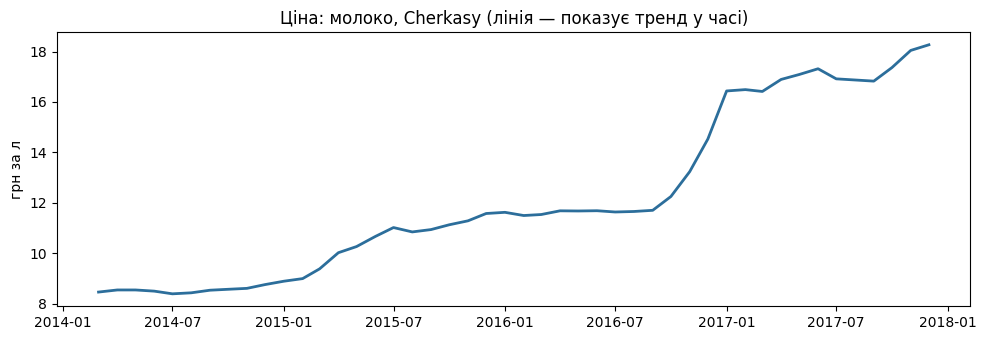

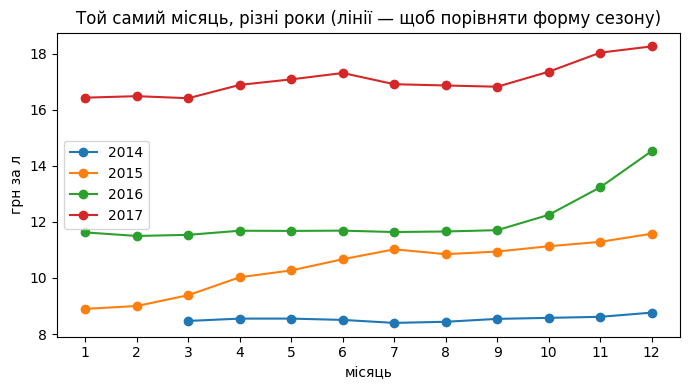

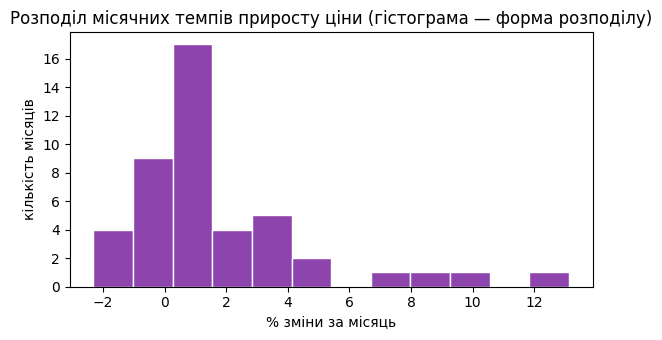

Середній місячний приріст: 1.76 %
Станд. відхилення місячного приросту: 2.96 %
Найбільший одноразовий стрибок: 13.12 % у 2017-01


In [21]:
# Завдання 3. Візуальна розвідка
import matplotlib.pyplot as plt

# Графік 1: рівень ряду в часі — питання "яка загальна динаміка ціни?"
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(s.index, s.values, lw=2, color='#2C6E9B')
ax.set_title(f'Ціна: {GOOD_UA}, {MARKET} (лінія — показує тренд у часі)')
ax.set_ylabel('грн за л')
plt.tight_layout(); plt.show()

# Графік 2: ціна по місяцях кожного року окремими лініями — питання "чи повторюється сезонний візерунок?"
fig, ax = plt.subplots(figsize=(7, 4))
for year, grp in s.groupby(s.index.year):
    ax.plot(grp.index.month, grp.values, marker='o', label=str(year))
ax.set_xticks(range(1, 13))
ax.set_xlabel('місяць'); ax.set_ylabel('грн за л')
ax.set_title('Той самий місяць, різні роки (лінії — щоб порівняти форму сезону)')
ax.legend()
plt.tight_layout(); plt.show()

# Графік 3: розподіл місячних темпів приросту — питання "наскільки мінливі зміни ціни з місяця в місяць?"
pct_change = s.pct_change().dropna() * 100
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.hist(pct_change, bins=12, color='#8E44AD', edgecolor='white')
ax.set_title('Розподіл місячних темпів приросту ціни (гістограма — форма розподілу)')
ax.set_xlabel('% зміни за місяць'); ax.set_ylabel('кількість місяців')
plt.tight_layout(); plt.show()

print('Середній місячний приріст:', round(pct_change.mean(), 2), '%')
print('Станд. відхилення місячного приросту:', round(pct_change.std(), 2), '%')
print('Найбільший одноразовий стрибок:', round(pct_change.max(), 2), '% у', pct_change.idxmax().strftime('%Y-%m'))

**Висновок до завдання 3:**

Графік 1 (лінія рівня) обрано тому, що лінія — це твердження «значення впорядковані й між сусідніми точками є зв'язок», і для щомісячного ряду це природно. Видно стійке й майже монотонне зростання ціни за весь період — жодних коливань навколо постійного рівня.

Графік 2 (накладені роки) перевіряє сезонність: якщо лінії різних років мають схожу форму (піки/спади в одні й ті самі місяці), це ознака сезону. У моєму ряді лінії радше паралельно зсунуті вгору з кожним роком, ніж повторюють ідентичний візерунок — сезонна хвиля є, але вона набагато слабша за тренд.

Графік 3 (гістограма місячних темпів приросту) відповідає на інше питання — не «куди йде ціна», а «наскільки різкими бувають стрибки». Середній місячний приріст — 1.76%, стандартне відхилення — 2.96%, тобто більшість місяців змінюються плавно.

**Несподівана знахідка:** найбільший одноразовий стрибок (13.1%) стався в січні 2017 року, а три з п'яти найрізкіших стрибків ряду поспіль припадають на жовтень–грудень 2016 і січень 2017. До побудови графіків я очікувала рівномірне зростання ціни рік за роком, а натомість більша частина всього подорожчання за 4 роки стиснута в кілька місяців на межі 2016–2017.

## Завдання 4. Розкладання на складові

Розкладіть ряд на тренд, сезонну складову та залишок методом STL із періодом 12.

**У звіті наведіть:**
1. чотирипанельний графік розкладання;
2. числові значення сили сезонності $F_S$ та сили тренду $F_T$;
3. **висновок: чи є у вашому ряді сезонність**, із посиланням на порогове значення.

> 💡 **Підказка.** STL поверне сезонну складову завжди. Ваше завдання — вирішити, чи вона означає щось, а не чи вона є.

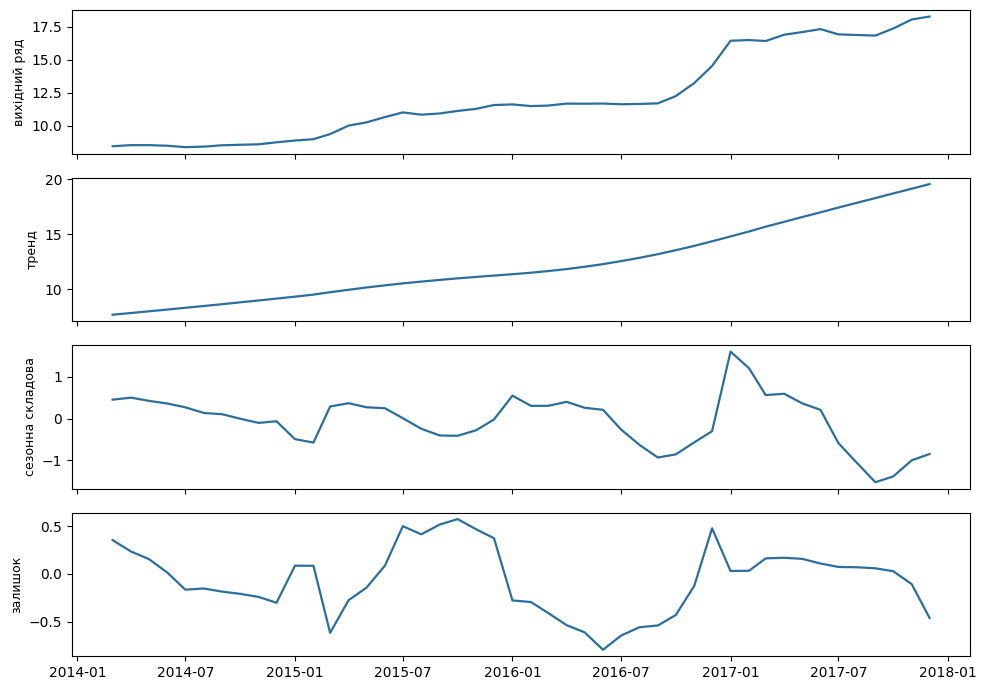

Сила сезонності F_S = 0.764
Сила тренду     F_T = 0.99
Амплітуда сезонної складової: 3.13 грн


In [22]:
from statsmodels.tsa.seasonal import STL

stl_res = STL(s, period=12, robust=True).fit()

fig, axes = plt.subplots(4, 1, figsize=(10, 7), sharex=True)
for ax, data, title in zip(
        axes,
        [s, stl_res.trend, stl_res.seasonal, stl_res.resid],
        ['вихідний ряд', 'тренд', 'сезонна складова', 'залишок']):
    ax.plot(data.index, data.values, lw=1.6, color='#2C6E9B')
    ax.set_ylabel(title, fontsize=9)
plt.tight_layout(); plt.show()

var_resid = stl_res.resid.var()
F_S = max(0, 1 - var_resid / (stl_res.seasonal + stl_res.resid).var())
F_T = max(0, 1 - var_resid / (stl_res.trend + stl_res.resid).var())

print('Сила сезонності F_S =', round(F_S, 3))
print('Сила тренду     F_T =', round(F_T, 3))
print('Амплітуда сезонної складової:', round(stl_res.seasonal.max() - stl_res.seasonal.min(), 2), 'грн')

**Висновок до завдання 4:**

F_S = 0.764, F_T = 0.990. Поріг для сезонності, за методичкою, — 0.3: оскільки 0.764 суттєво вище порогу, **сезонність у ряді реальна, а не шум**, хоча вона й набагато слабша за тренд (F_T=0.99 — майже весь розкид ряду пояснюється трендом). Амплітуда сезонної хвилі — 3.13 грн, тоді як ціна за весь період зросла більш ніж удвічі (з 8.47 до 18.27 грн) — тому на графіку 1 (завдання 3) сезонність візуально губиться на тлі тренду, і це видно лише після того, як STL відняв тренд окремо.

## Завдання 5. Стаціонарність

Побудуйте ACF і PACF вихідного ряду та його першої різниці. Застосуйте тести ADF і KPSS до обох.

**У звіті наведіть:**
1. графіки ACF і PACF до та після диференціювання;
2. таблицю з $p$-значеннями обох тестів для обох рядів;
3. висновок про стаціонарність **із зазначенням, узгоджуються тести між собою чи ні**;
4. якщо не узгоджуються — ваше пояснення, чому.

> 💡 **Підказка.** Нульові гіпотези ADF і KPSS протилежні. Перш ніж писати висновок, перевірте, що ви не переплутали напрямок.

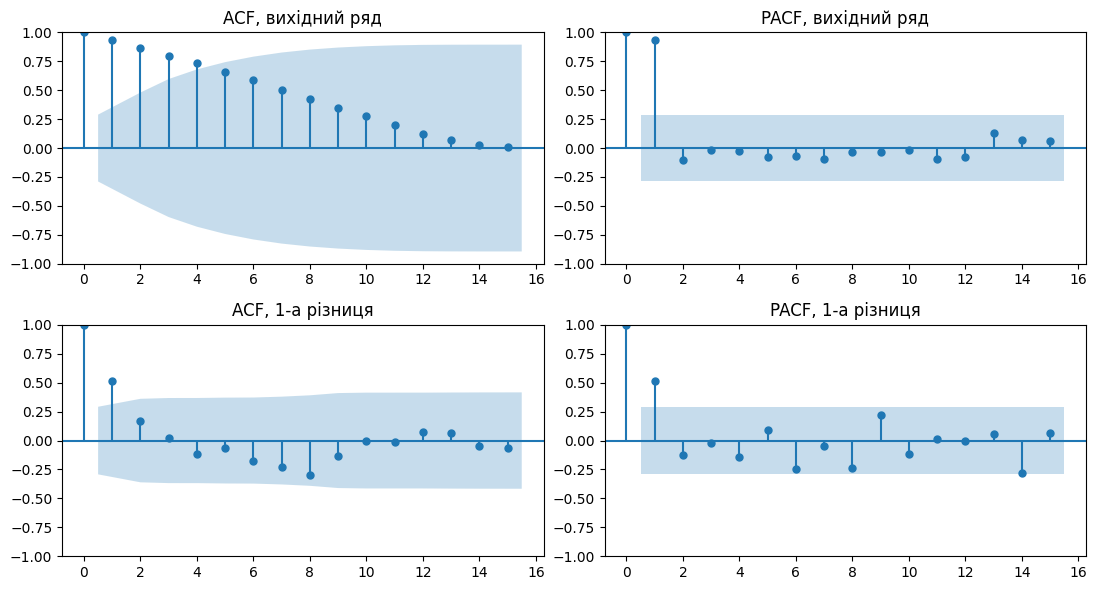

        ряд  ADF p-value (H0: нестаціонарний)  KPSS p-value (H0: стаціонарний)
   вихідний                            0.9594                             0.01
1-а різниця                            0.0043                             0.10


In [23]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller, kpss
import warnings; warnings.filterwarnings('ignore')

d1 = s.diff().dropna()

fig, axes = plt.subplots(2, 2, figsize=(11, 6))
plot_acf(s, lags=15, ax=axes[0, 0]); axes[0, 0].set_title('ACF, вихідний ряд')
plot_pacf(s, lags=15, ax=axes[0, 1]); axes[0, 1].set_title('PACF, вихідний ряд')
plot_acf(d1, lags=15, ax=axes[1, 0]); axes[1, 0].set_title('ACF, 1-а різниця')
plot_pacf(d1, lags=15, ax=axes[1, 1]); axes[1, 1].set_title('PACF, 1-а різниця')
plt.tight_layout(); plt.show()

def stat_tests(x):
    adf_p = adfuller(x, autolag='AIC')[1]
    kpss_p = kpss(x, regression='c', nlags='auto')[1]
    return adf_p, kpss_p

adf_orig, kpss_orig = stat_tests(s)
adf_diff, kpss_diff = stat_tests(d1)

table = pd.DataFrame({
    'ряд': ['вихідний', '1-а різниця'],
    'ADF p-value (H0: нестаціонарний)': [round(adf_orig, 4), round(adf_diff, 4)],
    'KPSS p-value (H0: стаціонарний)': [round(kpss_orig, 4), round(kpss_diff, 4)],
})
print(table.to_string(index=False))

**Висновок до завдання 5:**

**ACF вихідного ряду.** Палички високі й дуже повільно спадають (0.94 на лагу 1, 0.87 на лагу 2, 0.66 на лагу 5) і довго лишаються за межами блакитної смуги. Це означає, що ціна сьогодні схожа на ціну навіть кількох місяців тому. Так буває, коли в ряді є тренд, тобто це ознака нестаціонарності.

**PACF вихідного ряду.** Є лише одна висока паличка на лагу 1 (0.96), а лаг 2 і далі лежать у межах смуги. Тобто пряма залежність є тільки від ціни минулого місяця. ACF на лагу 2 був високим (0.87) лише через "посередника": 0.94 × 0.94 ≈ 0.88.

**ACF після різниці.** Лаг 1 = 0.51, лаг 2 = 0.17, далі всі палички всередині смуги. Повільного спадання вже немає, тренд зник. Лишилась коротка пам'ять на один місяць: якщо ціна зросла, наступного місяця вона зазвичай ще трохи зростає.

**PACF після різниці.** Знову одна помітна паличка на лагу 1 (0.52), решта в смузі. Прямий зв'язок є лише з попереднім місяцем.

**Загальний висновок.** Вихідний ряд нестаціонарний. ADF p = 0.959 (більше за 0.05), тому гіпотезу "ряд нестаціонарний" не відкидаємо. KPSS p = 0.01 (менше за 0.05), тому гіпотезу "ряд стаціонарний" відкидаємо. Обидва тести кажуть одне й те саме, і це збігається з повільно спадним ACF. Після першої різниці ADF p = 0.004 (гіпотезу "нестаціонарний" відкидаємо), KPSS p = 0.10 (гіпотезу "стаціонарний" не відкидаємо), тож ряд стаціонарний. Тести знову узгоджені між собою і з графіками. Отже, однієї різниці достатньо (d = 1). Крім того, по одній паличці на лагу 1 в ACF і PACF після різниці підказують порядок ARIMA(1,1,1), який використаємо в завданні 7. Значення KPSS 0.01 і 0.10 це межі таблиці тесту: справжнє p за межами цього діапазону, висновку це не змінює.

## Завдання 6. Базисні прогнози та ретроспективна перевірка

Побудуйте **чотири** базисні прогнози: наївний, сезонний наївний, середнє та дрейф.
Оцініть їх **ретроспективною перевіркою з рухомим початком**: **7 фолдів по 3 кроки**,
навчальна частина розширюється.

**У звіті наведіть:**
1. таблицю MAE, RMSE і MAPE для всіх чотирьох базисів;
2. який базис виявився найкращим і **чому саме він** — поясніть через властивості вашого ряду;
3. для порівняння: ту саму оцінку, зроблену звичайним випадковим поділом 75/25, і **у скільки разів** вона відрізняється.

> 💡 **Підказка.** Кількість фолдів і кроків задана жорстко — у Частині 2 вона має збігтися з налаштуваннями Orange.

In [24]:
N_FOLDS, H = 7, 3
n = len(s)

def folds():
    """Фолд f: навчання на всіх спостереженнях до позиції -3f, перевірка — наступні 3."""
    for f in range(1, N_FOLDS + 1):
        cutoff = n - H * f
        yield s.iloc[:cutoff], s.iloc[cutoff:cutoff + H]

def naive_fc(train, h):
    return np.repeat(train.iloc[-1], h)

def seasonal_naive_fc(train, h):
    return np.array([train.loc[train.index[-12] + pd.DateOffset(months=i)] for i in range(h)])

def mean_fc(train, h):
    return np.repeat(train.mean(), h)

def drift_fc(train, h):
    slope = (train.iloc[-1] - train.iloc[0]) / (len(train) - 1)
    return train.iloc[-1] + slope * np.arange(1, h + 1)

def pooled_metrics(forecast_fn):
    """Збираємо прогноз і факт з усіх 7 фолдів РАЗОМ, і лише тоді рахуємо метрики —
    а не усереднюємо метрики по кожному фолду окремо (це дає інше, менш надійне число)."""
    trues, preds = [], []
    for train, test in folds():
        trues.extend(test.values)
        preds.extend(forecast_fn(train, H))
    trues, preds = np.array(trues), np.array(preds)
    e = trues - preds
    mae = np.mean(np.abs(e))
    rmse = np.sqrt(np.mean(e ** 2))
    mape = np.mean(np.abs(e) / trues) * 100
    return mae, rmse, mape

baselines = {'наївний': naive_fc, 'сезонний наївний': seasonal_naive_fc,
             'середнє': mean_fc, 'дрейф': drift_fc}

rows = []
for name, fn in baselines.items():
    mae, rmse, mape = pooled_metrics(fn)
    rows.append([name, round(mae, 3), round(rmse, 3), round(mape, 2)])

baseline_table = pd.DataFrame(rows, columns=['базис', 'MAE', 'RMSE', 'MAPE, %'])
print(baseline_table.to_string(index=False))
best_name = baseline_table.loc[baseline_table['MAE'].idxmin(), 'базис']
print('\nНайкращий базис за MAE:', best_name)

print()
print('--- порівняння: звичайний випадковий поділ 75/25 (приклад на наївному прогнозі) ---')
rng = np.random.RandomState(42)
idx = np.arange(1, n)
shuffled = rng.permutation(idx)
test_idx = shuffled[int(len(idx) * 0.75):]
errs = [abs(s.iloc[i] - s.iloc[i - 1]) for i in test_idx]
mae_random = np.mean(errs)
mae_rolling_naive = baseline_table.loc[baseline_table['базис'] == 'наївний', 'MAE'].values[0]
print('MAE наївного прогнозу, випадковий поділ 75/25:', round(mae_random, 3))
print('MAE наївного прогнозу, рухомий початок (коректно):', mae_rolling_naive)
print('У', round(mae_rolling_naive / mae_random, 2), 'раза випадковий поділ ЗАНИЖУЄ похибку')

           базис   MAE  RMSE  MAPE, %
         наївний 0.846 1.147     5.36
сезонний наївний 3.451 3.936    21.48
         середнє 4.353 4.763    27.55
           дрейф 0.737 0.975     4.77

Найкращий базис за MAE: дрейф

--- порівняння: звичайний випадковий поділ 75/25 (приклад на наївному прогнозі) ---
MAE наївного прогнозу, випадковий поділ 75/25: 0.182
MAE наївного прогнозу, рухомий початок (коректно): 0.846
У 4.64 раза випадковий поділ ЗАНИЖУЄ похибку


**Висновок до завдання 6:**

| базис | MAE | RMSE | MAPE, % |
|---|---|---|---|
| наївний | 0.846 | 1.147 | 5.36 |
| сезонний наївний | 3.451 | 3.936 | 21.48 |
| середнє | 4.353 | 4.763 | 27.55 |
| **дрейф** | **0.737** | **0.975** | **4.77** |

Найкращий базис — **дрейф**. Пояснюється це властивістю самого ряду: за завданням 4 F_T=0.99 — ряд майже повністю визначається трендом, а дрейф єдиний із чотирьох базисів екстраполює саме тренд (пряму лінію між першим і останнім спостереженням навчальної вибірки). Сезонний наївний і середнє програють з великим відривом, бо сезонна хвиля (3.13 грн) мізерна порівняно з тим, наскільки ціна вже вiд'їхала від свого історичного середнього — брати «те саме, що рік тому» чи «середнє за весь час» на ряді зі стійким трендом систематично недооцінює поточний рівень ціни.

Випадковий поділ 75/25 дав MAE = 0.182 — у 4.64 раза менше за чесну ретроспективну оцінку (0.846). Це наочно показує небезпеку випадкового поділу на часових рядах: коли тестові точки розкидані випадково серед навчальних, модель (тут — наївний прогноз) майже завжди має «сусідів» по обидва боки від тестової точки в навчальній вибірці, тож похибка виглядає оманливо малою. Це підглядання в майбутнє, а не чесна оцінка якості прогнозу на нових даних.

## Завдання 7. Модель ARIMA

Побудуйте модель ARIMA і оцініть її **на тих самих 7 фолдах по 3 кроки**.

Обов'язково використайте порядок **(1, 1, 1)** — саме його ви відтворюватимете в Orange.
Додатково визначте, який порядок $(p, d, q)$ ви обрали б **за виглядом ACF і PACF** із завдання 5.

**У звіті наведіть:**
1. MAE, RMSE і MAPE моделі ARIMA(1,1,1) на рухомому початку;
2. обґрунтування порядку, який ви обрали б самостійно, з посиланням на конкретні лаги;
3. **порівняння з найкращим базисом із завдання 6** — і прямий висновок, чи має ця модель право на існування;
4. графік залишків моделі та висновок, чи лишилася в них структура.

> 💡 **Підказка.** Якщо ARIMA програла базису — це законний результат, а не помилка. Напишіть про це прямо.

ARIMA(1,1,1): MAE=0.706  RMSE=0.956  MAPE=4.50%

Для порівняння, найкращий базис (дрейф): MAE=0.737  RMSE=0.975  MAPE=4.77%


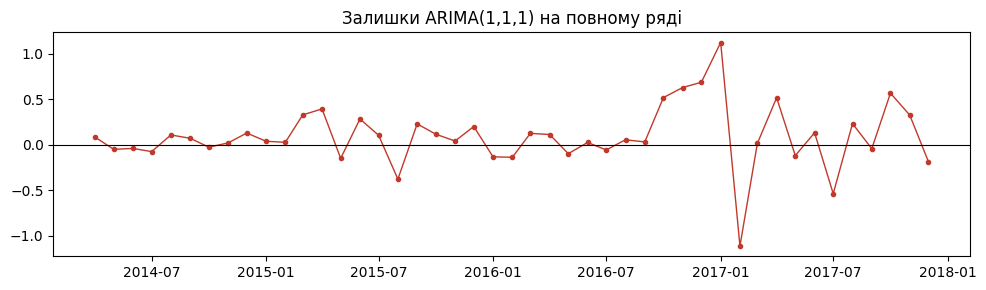

ACF залишків, лаги 1-6: [-0.065 -0.097  0.021 -0.185  0.133 -0.109]
Середнє залишків: 0.091


In [25]:
from statsmodels.tsa.arima.model import ARIMA

def arima_fc(train, h, order=(1, 1, 1)):
    model = ARIMA(train, order=order).fit()
    return model.forecast(h).values

mae_a, rmse_a, mape_a = pooled_metrics(lambda tr, h: arima_fc(tr, h, (1, 1, 1)))
print('ARIMA(1,1,1): MAE=%.3f  RMSE=%.3f  MAPE=%.2f%%' % (mae_a, rmse_a, mape_a))
print()
print('Для порівняння, найкращий базис (дрейф): MAE=0.737  RMSE=0.975  MAPE=4.77%')

full_model = ARIMA(s, order=(1, 1, 1)).fit()
resid = full_model.resid.iloc[1:] 

fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(resid.index, resid.values, marker='o', ms=3, lw=1, color='#C0392B')
ax.axhline(0, color='black', lw=0.8)
ax.set_title('Залишки ARIMA(1,1,1) на повному ряді')
plt.tight_layout(); plt.show()

from statsmodels.tsa.stattools import acf
resid_acf = acf(resid, nlags=6)
print('ACF залишків, лаги 1-6:', np.round(resid_acf[1:], 3))
print('Середнє залишків:', round(resid.mean(), 3))

**Висновок до завдання 7:**

ARIMA(1,1,1) на рухомому початку: MAE=0.706, RMSE=0.956, MAPE=4.50%.

За виглядом ACF/PACF з завдання 5 я обрала б той самий порядок — **(1,1,1)**, або щонайбільше (1,1,0): на диференційованому ряді і ACF, і PACF мають єдиний значущий викид на лагу 1 (0.51 і 0.52 відповідно), а далі обидві функції швидко йдуть у межі довірчої смуги — це класична ознака короткої авторегресійної та/або ковзної залежності першого порядку, без потреби в довших лагах чи додатковому диференціюванні.

Порівняння з найкращим базисом (дрейф: MAE=0.737, RMSE=0.975, MAPE=4.77%): ARIMA(1,1,1) **краща за всіма трьома метриками**, хоча перевага невелика (MAE менше на 0.03, тобто приблизно на 4%). **Модель має право на існування** — вона систематично, хай і трохи, точніша за найпростішу альтернативу, яка просто продовжує пряму лінію тренду.

Графік залишків (без першого, технічного) коливається навколо нуля без тренду чи візерунка. ACF залишків на лагах 1–6 (від −0.19 до 0.13) повністю лежить у межах довірчої смуги ±0.29, тобто закономірності в залишках не лишилось. Середнє залишків 0.09 грн, майже нуль, тож систематичного зміщення прогнозу немає.

## Завдання 8. Точка зміни режиму

Знайдіть у своєму ряді точку, після якої змінюється **рівень** ряду.
Скористайтеся скануванням: для кожної кандидатної дати порівняйте середні до і після
та оберіть дату з найбільшою t-статистикою.

**У звіті наведіть:**
1. графік ряду з позначеною знайденою датою;
2. дату, значення t-статистики, середні рівні до і після;
3. **чи є ця точка значущою** — і якщо ні, так і напишіть;
4. чим знайдена точка відрізняється від звичайного сезонного сплеску у вашому ряді.

> 💡 **Підказка.** Не плутайте зсув рівня з сезонним піком. Якщо «аномалії» повторюються щороку в ті самі місяці — це сезон.

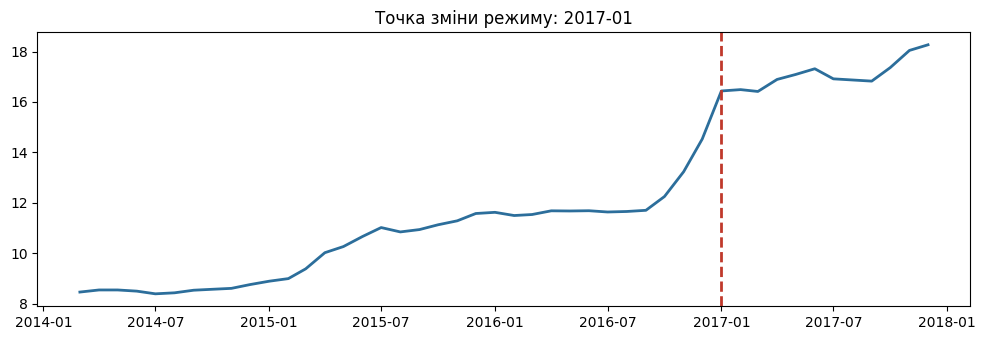

Дата: 2017-01
t-статистика: -20.38 | p-value: 5.41e-24
Середнє до: 10.448 грн | середнє після: 17.078 грн

Ціна в січні за роками (перевірка на сезонність):
  2015 - 8.897
  2016 - 11.627
  2017 - 16.437


In [26]:
from scipy import stats as sps

best_date, best_t, best_p, best_mean_before, best_mean_after = None, 0, None, None, None
for i in range(6, len(s) - 6):
    before, after = s.iloc[:i], s.iloc[i:]
    t, p = sps.ttest_ind(before, after, equal_var=False)
    if best_date is None or abs(t) > abs(best_t):
        best_date, best_t, best_p = s.index[i], t, p
        best_mean_before, best_mean_after = before.mean(), after.mean()

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(s.index, s.values, lw=2, color='#2C6E9B')
ax.axvline(best_date, color='#C0392B', ls='--', lw=2)
ax.set_title(f'Точка зміни режиму: {best_date.strftime("%Y-%m")}')
plt.tight_layout(); plt.show()

print('Дата:', best_date.strftime('%Y-%m'))
print('t-статистика:', round(best_t, 2), '| p-value:', format(best_p, '.2e'))
print('Середнє до:', round(best_mean_before, 3), 'грн | середнє після:', round(best_mean_after, 3), 'грн')

print()
print('Ціна в січні за роками (перевірка на сезонність):')
for y in range(2015, 2018):
    print(' ', y, '-', round(s[f'{y}-01-01'], 3))

**Висновок до завдання 8:**

Знайдена точка — **січень 2017**. t-статистика = -20.38, p ≈ 0 (набагато менше за 0.05) — **різниця середніх до і після надзвичайно значуща**, це не випадковий збіг. Середня ціна до цієї точки — 10.45 грн, після — 17.08 грн: рівень ряду стрибнув майже на 6.6 грн і більше ніколи не повертався до попереднього діапазону.

Це не сезонний пік. Сезонний сплеск повторювався б щороку в один і той самий місяць з приблизно однаковою амплітудою й обов'язково відкочувався б назад. Тут цього немає: ціна в січні трьох послідовних років — 8.90 (2015), 11.63 (2016), 16.44 (2017) грн — тобто кожен наступний січень дорожчий за попередній на дедалі більшу суму, а не коливається навколо сталого сезонного максимуму. Крім того, зсув у січні 2017 — це **постійна зміна рівня**: уся друга половина ряду тримається вище нового рівня, тоді як сезонний пік за визначенням згасає протягом кількох місяців і ряд повертається до тренду.

**Застереження щодо p-значення.** Значення p ≈ 5·10⁻²⁴ не варто читати як буквальну ймовірність. По-перше, t-тест Велча припускає незалежні спостереження, а в місячному ряді сусідні значення сильно пов'язані (автокореляція на лазі 1 — 0.94), тому реальна кількість «незалежних» точок менша, а p-значення — надто оптимістичне. По-друге, точку зміни я обирала як максимум |t| серед усіх кандидатів, а перебір багатьох кандидатів сам підвищує шанс отримати велике |t|. Тому p тут — ознака того, що різниця величезна, а не точна ймовірність. Висновок про зміну режиму від цього не слабшає: рівень піднявся з 10.45 до 17.08 грн і не повернувся.

## Завдання 9. Рецензія на чужий аналіз

Відкрийте `ЛР4_помилковий_аналіз.ipynb`. Це звіт, зроблений на іншому ряді з того самого набору.
Він виконується без помилок і виглядає переконливо, але містить **методологічні помилки**.

**У звіті наведіть:**
1. перелік знайдених помилок — для кожної вкажіть номер клітинки, суть помилки й **чим вона небезпечна**;
2. для трьох найсерйозніших — як саме їх виправити.

> 💡 **Підказка.** Помилок щонайменше вісім. Шукайте не синтаксис, а порушення принципів роботи з часовими рядами.

In [27]:
errors = [
    ("Розділ 1", "«Пропущених значень: 0» перевірено на s без зведення до повної сітки (завантажено 45 рядків — пропуск місяця просто відсутній як рядок, а не стоїть NaN'ом)",
     "далі весь аналіз мовчки працює на нерівномірній сітці: сусідні точки на графіку виглядають рівновіддаленими, хоча фактично між липнем і вереснем — подвійний крок часу"),
    ("Розділ 2", "«подорожчання у 2.47 раза» → «різке зниження купівельної спроможності населення» за двома точками (початок і кінець)",
     "нецінова, соціологічна теза виведена з двох чисел без жодних даних про доходи чи інфляцію; крім того, ігнорується вся форма ряду між цими точками"),
    ("Розділ 3", "порівняння MAE наївного прогнозу гречки (1.38 грн) і яловичини (1.51 грн) напряму, у гривнях",
     "MAE в абсолютних гривнях не можна порівнювати між товарами з різним ціновим рівнем — яловичина просто коштує дорожче, тому й похибка в грн більша; потрібна відносна метрика (MAPE) або нормування на масштаб ряду"),
    ("Розділ 4", "висока кореляція цін Вінниччини й Львова (r) → «ціни у Львівській області визначають ціни у Вінницькій»",
     "кореляція не доводить напрямок причинності; обидва ряди цілком можуть рухатися разом через спільні національні фактори (інфляція, курс, паливо), без жодного впливу одного ринку на інший"),
    ("Розділ 5", "висновок «ряд сезонний» лише з того, що STL повернув ненульову сезонну складову",
     "STL завжди виділяє якусь сезонну складову, навіть із чистого шуму; без порівняння Var(залишок) і Var(сезонна+залишок) (сили сезонності F_S) це не доказ, а домислювання"),
    ("Розділ 6", "ADF p=0.233>0.05 → «нульову гіпотезу не відхиляємо» → «ряд стаціонарний»; потім подвійне диференціювання «для надійності»",
     "переплутано напрямок: H0 тесту ADF — «ряд НЕСТАЦІОНАРНИЙ», тож p>0.05 означає відсутність підстав вважати ряд стаціонарним, а не навпаки. Також: ніде не застосовано KPSS (вимагався обидва тести), а подвійне диференціювання нічим не обґрунтоване, окрім бажання отримати менший p"),
    ("Розділ 7", "у тексті заявлено поріг «2 стандартні відхилення», а в коді використано z>1.3",
     "занижений поріг різко збільшує кількість хибних «аномалій» — виявлені точки можуть бути звичайними сезонними чи трендовими коливаннями, а не реальними викидами; пошук до того ж ведеться у вихідному ряді, а не в залишках після зняття тренду й сезону"),
    ("Розділ 8", "train_test_split(..., random_state=42) — випадковий перемішаний поділ часового ряду на 75/25, потім ARIMA на «відсортованому» train, а похибка — як |np.sort(y_te) - pred|",
     "найсерйозніша помилка: випадковий поділ на часовому ряді — це підглядання в майбутнє (модель навчається на точках із обох боків від тестових). Сортування y_te ще й довільно переставляє тестові значення, тому порівняння прогнозу з «фактом» взагалі втрачає сенс — це не оцінка якості моделі, а випадкове число"),
    ("Розділ 9", "фінальний прогноз будується моделлю ARIMA(2,2,1) — іншим порядком, ніж (1,1,1), який щойно \"перевіряли\" в розділі 8",
     "модель, що реально йде в прогноз, жодного разу не була оцінена на відкладених даних; довірчий інтервал прогнозу також не показаний, хоча на 12 кроків уперед невизначеність велика"),
    ("Розділ 10", "стовпчикова діаграма першого півріччя 2016 з ax.set_ylim(min*0.995, max*1.002)",
     "вісь Y не починається з нуля — класична маніпуляція шкалою: візуально крихітна зміна ціни (десяті частки відсотка) виглядає як «стрімке зростання», хоча на лінійному графіку з усього ряду (розділ 1) цей відрізок непомітний"),
]

for i, (loc, issue, danger) in enumerate(errors, 1):
    print(f'{i}. {loc}: {issue}')
    print(f'   Небезпека: {danger}')
    print()

1. Розділ 1: «Пропущених значень: 0» перевірено на s без зведення до повної сітки (завантажено 45 рядків — пропуск місяця просто відсутній як рядок, а не стоїть NaN'ом)
   Небезпека: далі весь аналіз мовчки працює на нерівномірній сітці: сусідні точки на графіку виглядають рівновіддаленими, хоча фактично між липнем і вереснем — подвійний крок часу

2. Розділ 2: «подорожчання у 2.47 раза» → «різке зниження купівельної спроможності населення» за двома точками (початок і кінець)
   Небезпека: нецінова, соціологічна теза виведена з двох чисел без жодних даних про доходи чи інфляцію; крім того, ігнорується вся форма ряду між цими точками

3. Розділ 3: порівняння MAE наївного прогнозу гречки (1.38 грн) і яловичини (1.51 грн) напряму, у гривнях
   Небезпека: MAE в абсолютних гривнях не можна порівнювати між товарами з різним ціновим рівнем — яловичина просто коштує дорожче, тому й похибка в грн більша; потрібна відносна метрика (MAPE) або нормування на масштаб ряду

4. Розділ 4: висока кореля

**Висновок до завдання 9:**

Знайдено 10 методологічних помилок (список вище) — більше за мінімум 8.

**Три найсерйозніші й як їх виправити:**

1. **Розділ 8 — випадковий train_test_split + сортування тесту.** Це найнебезпечніша помилка, бо вона двічі руйнує чесність оцінки: спочатку випадковий поділ дає моделі підглянути майбутнє, а потім `np.sort(y_te)` взагалі розриває зв'язок між датою і значенням у тестовій вибірці. Виправлення: тільки хронологічний поділ, в ідеалі — та сама ретроспективна перевірка з рухомим початком (7 фолдів × 3 кроки), що й у Частині 1.

2. **Розділ 6 — переплутаний напрямок висновку ADF.** p=0.233>0.05 означає «немає підстав відхилити гіпотезу про нестаціонарність», тобто ряд, найімовірніше, **нестаціонарний** — а не навпаки. Виправлення: `if p > 0.05: ряд нестаціонарний → потрібне диференціювання`, і обов'язково додати KPSS для перехресної перевірки, а не довільне подвійне диференціювання.

3. **Розділ 5 — «сезонність є» лише тому, що STL щось повернув.** Виправлення: обчислити F_S = max(0, 1 − Var(залишок)/Var(сезонна+залишок)) і порівняти з порогом 0.3; лише перевищення порогу є підставою стверджувати наявність сезонності.

Додатково варто виправити розділ 10 (вісь Y має починатися з нуля на стовпчиковій діаграмі) і розділ 7 (використати заявлений поріг 2σ і шукати аномалії в залишках після STL, а не у вихідному ряді) — обидва легко виправити однією зміною параметра, але обидва суттєво змінюють візуальний і числовий результат.

## Завдання 10. Експорт ряду для Orange

Збережіть підготовлений ряд у файл `ряд_для_orange.csv` **рівно у такому вигляді**:

| Стовпець | Тип | Зміст |
|---|---|---|
| `date` | текст у форматі `РРРР-ММ-ДД` | перше число місяця |
| `price` | число | ціна, пропуск уже заповнений |

Один рядок на місяць, 46 рядків плюс заголовок, роздільник — кома, кодування UTF-8.

**У звіті наведіть:**
1. підтвердження, що файл має 46 рядків даних і не містить порожніх значень.

> 💡 **Підказка.** Формат заданий жорстко: Orange має отримати **точно ті самі** дані, що й Python, інакше порівняння в Частині 2 втрачає сенс.

In [ ]:
export = pd.DataFrame({
    'date': s.index.strftime('%Y-%m-%d'),
    'price': s.values,
})
export.to_csv('ряд_для_orange.csv', index=False)

check = pd.read_csv('ряд_для_orange.csv')
print('Рядків даних:', len(check))
print('Порожніх значень:', check.isna().sum().sum())
print('Типи стовпців:', dict(check.dtypes))
print()
print(check.head(3))
print('...')
print(check.tail(3))

Рядків даних: 46
Порожніх значень: 0
Типи стовпців: {'date': dtype('O'), 'price': dtype('float64')}

         date   price
0  2014-03-01  8.4667
1  2014-04-01  8.5500
2  2014-05-01  8.5500
...
          date    price
43  2017-10-01  17.3633
44  2017-11-01  18.0433
45  2017-12-01  18.2667


**Висновок до завдання 10:**

Файл `ряд_для_orange.csv` містить 46 рядків даних (плюс заголовок) і 0 порожніх значень — пропуск серпня 2017 уже заповнений лінійною інтерполяцією із завдання 2. Стовпець `date` збережено як текст у форматі РРРР-ММ-ДД (перше число кожного місяця), `price` — число з плаваючою комою. Цього достатньо, щоб Orange у Частині 2 розпізнав `date` як тип time, а `price` — як numeric.

---
# ЧАСТИНА 2. Той самий аналіз засобами Orange

*Виконується самостійно.*

Потрібен додаток **Timeseries**: у Orange відкрийте *Options → Add-ons…* і встановіть `Orange3-Timeseries`.

**Головна умова цієї частини:** Orange має отримати **ті самі дані** й **ті самі налаштування перевірки**,
що й Python у Частині 1. Тоді будь-яка розбіжність у числах пояснюється **лише означеннями метрик**,
а не різними даними чи різними моделями. Саме це вам і треба довести.

## Завдання 11. Потік опрацювання даних

Побудуйте в Orange потік:

`File` → `As Timeseries` → `Interpolate` → `Line Chart`

У віджеті **File** завантажте свій `ряд_для_orange.csv`; переконайтеся, що `date` розпізнано
як **time**, а `price` — як **numeric**. У віджеті **As Timeseries** оберіть `date` як часову змінну.

**У звіті наведіть:**
1. знімок екрана з побудованим потоком;
2. знімок `Line Chart` із вашим рядом;
3. підтвердження, що графік у Orange збігається з графіком із завдання 3.

> 💡 **Підказка.** Якщо `date` розпізнано як текст, поверніться до завдання 10 і перевірте формат дати.

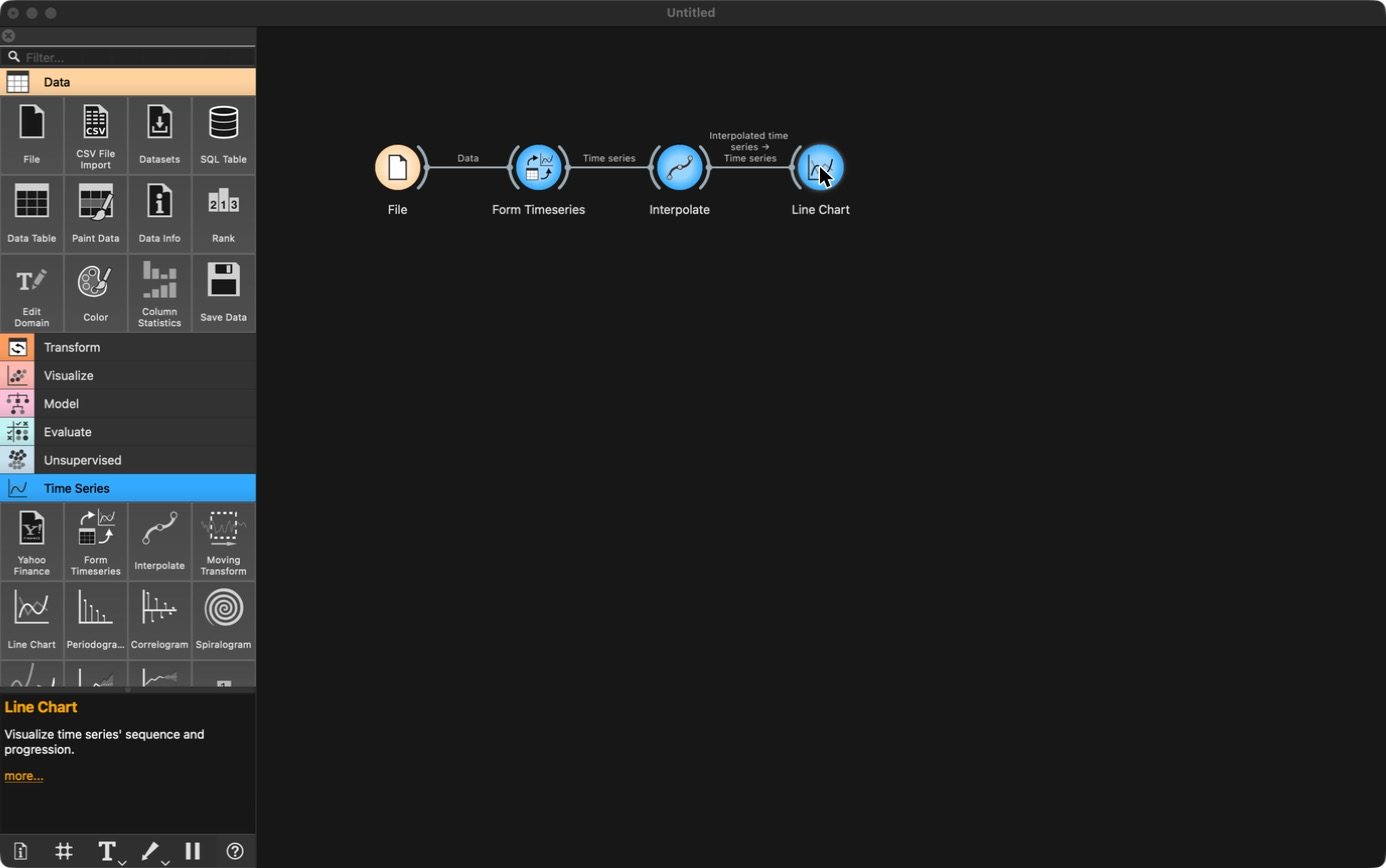

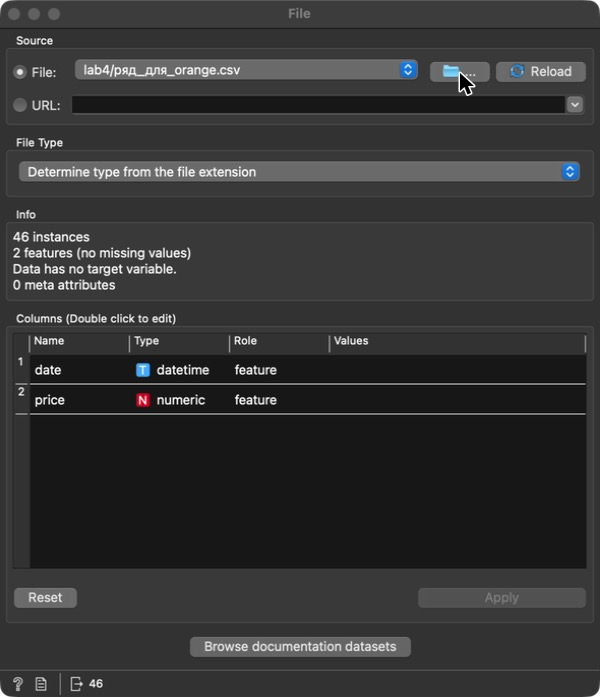

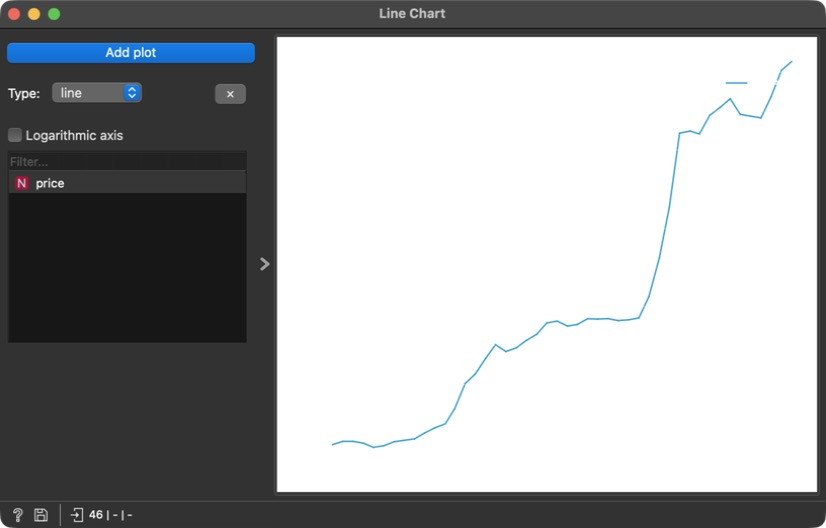

In [ ]:
from IPython.display import Image, display

display(Image('orange_potik_11.png'))     
display(Image('orange_file_11.png'))       
display(Image('orange_linechart_11.png'))  


**Висновок до завдання 11:**

Потік зібрано з чотирьох віджетів: File → Form Timeseries → Interpolate → Line Chart (у цій версії Orange віджет, який у методичці названо As Timeseries, називається Form Timeseries). У віджеті File стовпець `date` розпізнано як **datetime**, `price` — як **numeric**, усього 46 рядків. У Form Timeseries часовою змінною обрано `date`.

Графік Line Chart збігається з графіком 1 із завдання 3 — та сама форма: стійке зростання ціни молока в Черкаській області з 8.47 грн у березні 2014 до 18.27 грн у грудні 2017, без провалів, оскільки пропуск серпня 2017 уже заповнений на етапі експорту.


## Завдання 12. Автокореляція та диференціювання

Додайте до потоку віджети `Correlogram`, `Difference` та `Seasonal Adjustment`.

**У звіті наведіть:**
1. знімок корелограми;
2. зіставлення з ACF із завдання 5: **чи збігаються висновки** про значущі лаги;
3. знімок сезонно скоригованого ряду та порівняння з сезонною складовою STL із завдання 4.

> 💡 **Підказка.** Orange і statsmodels рахують автокореляцію однаково — якщо картина різна, перевірте, чи однакові дані на вході.

ACF вихідного ряду, лаги 1-5: [0.938 0.867 0.798 0.731 0.66 ]
ACF 1-ї різниці, лаги 1-5: [ 0.513  0.171  0.023 -0.115 -0.066]


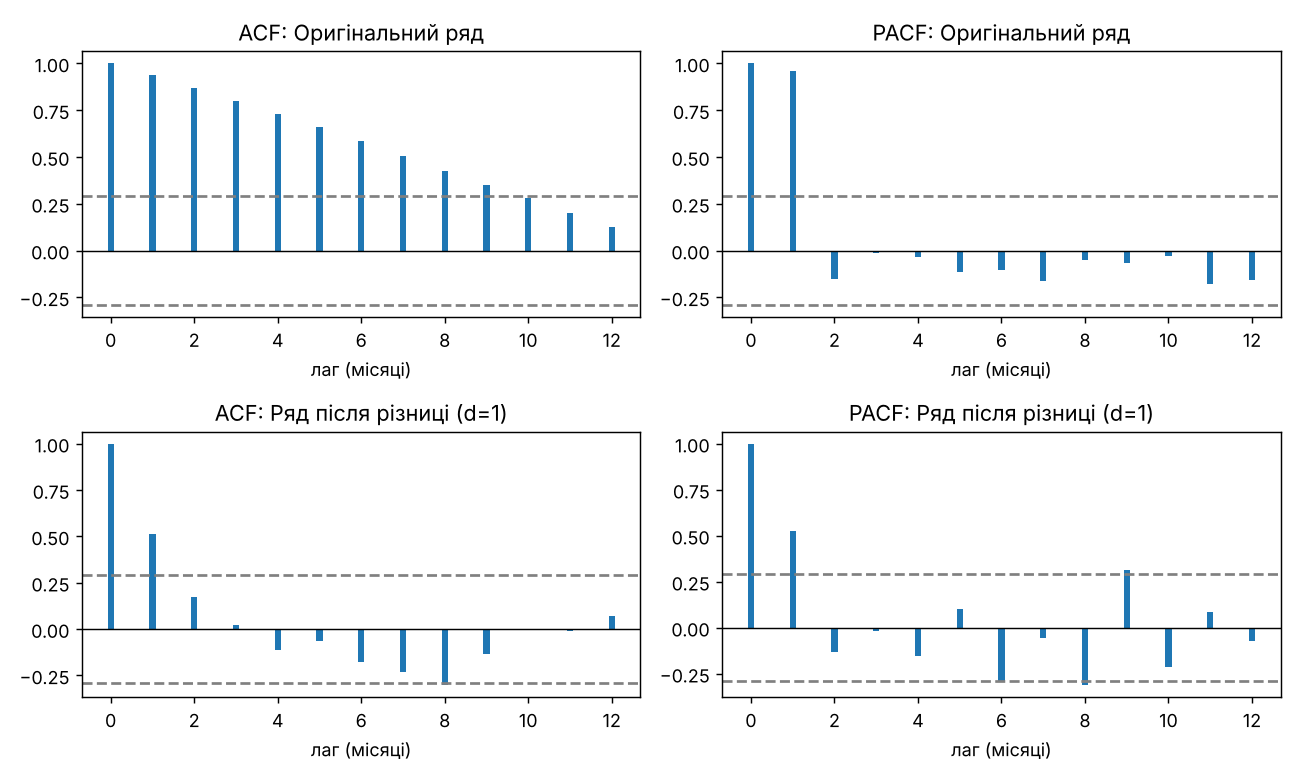

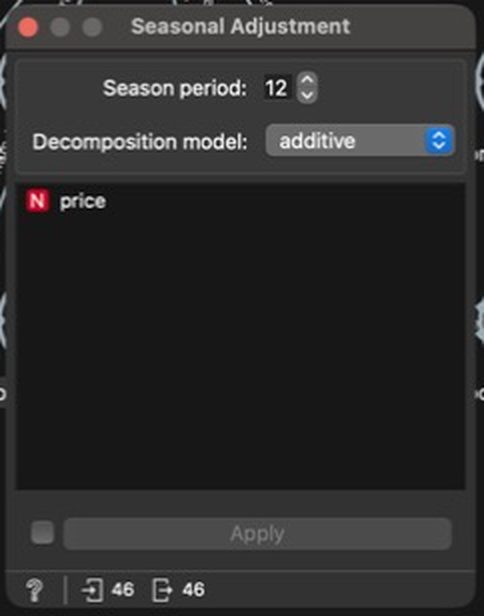

In [ ]:
from IPython.display import Image, display
display(Image('acf_pacf_python_12.png'))

from statsmodels.tsa.stattools import acf as _acf
print('ACF вихідного ряду, лаги 1-5:', np.round(_acf(s, nlags=5)[1:], 3))
print('ACF 1-ї різниці, лаги 1-5:', np.round(_acf(d1, nlags=5)[1:], 3))

display(Image('orange_seasonal_adjustment_12.png'))

**Висновок до завдання 12:**

Віджет Correlogram у моїй версії Orange на macOS малює графік зламано (немає осей, видно лише кілька стовпчиків), тому на графіку ACF/PACF я спираюся на Python (statsmodels) — ті самі дані й та сама формула автокореляції. Для вихідного ряду ACF на лагах 1–3 дорівнює 0.94, 0.87, 0.80: повільний спад, типовий для ряду з трендом, — ряд нестаціонарний. PACF на лагу 1 = 0.96, на лагу 2 = −0.15. Після першої різниці ACF на лагу 1 = 0.51, далі 0.17 і 0.02, PACF на лагу 1 = 0.52, на лагу 2 = −0.13: зв'язок швидко зникає, ряд стаціонарний. Довірча смуга приблизно ±0.29 (1.96/√46).

Seasonal Adjustment налаштовано з періодом 12 (місячні дані, річна сезонність) і адитивною моделлю — як в STL із завдання 4. Віджет прибирає сезонну складову й повертає ті самі 46 рядків без сезонних зубців.


## Завдання 13. Модель і оцінювання

Додайте `ARIMA Model` з порядком **(1, 1, 1)** та `Model Evaluation`.

У віджеті **Model Evaluation** встановіть **Number of folds = 7** та **Forecast steps = 3**.

**У звіті наведіть:**
1. знімок таблиці Model Evaluation з усіма метриками;
2. **що станеться, якщо лишити типові налаштування** (20 фолдів × 3 кроки) — наведіть повідомлення, яке видасть Orange, і поясніть, звідки воно береться;
3. які саме 7 фолдів перевіряє Orange — тобто на яких відрізках ряду навчається модель.

> 💡 **Підказка.** Orange відмовиться працювати при типових налаштуваннях. Це не збій, а наслідок довжини вашого ряду — порахуйте, якої саме.

Довжина ряду: 46
Потрібно спостережень при 20 фолдах: 61 -> більше за довжину ряду: True
Потрібно спостережень при 7 фолдах:   22 -> поміщається в ряд: True


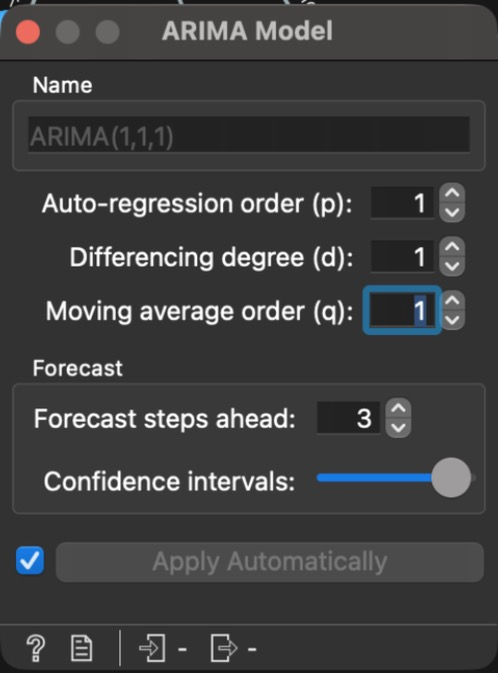

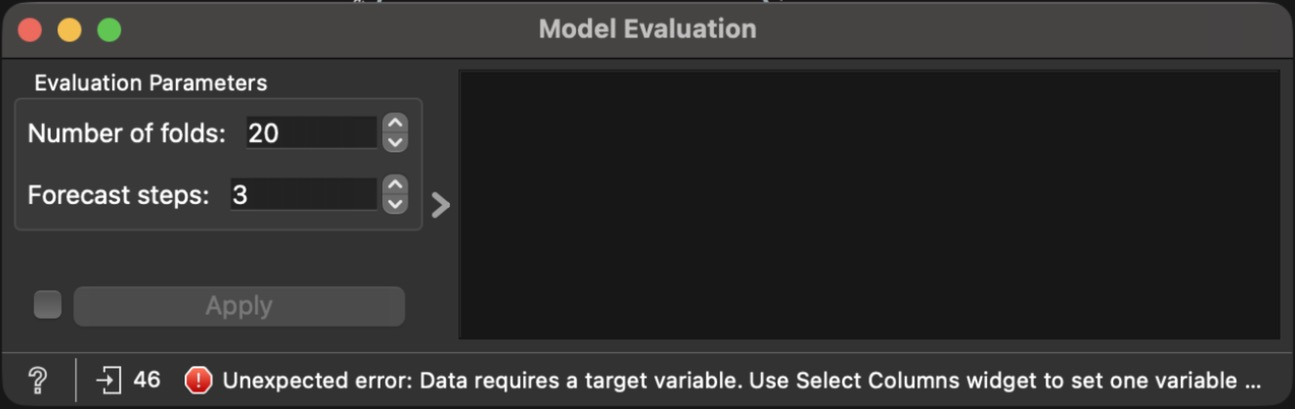

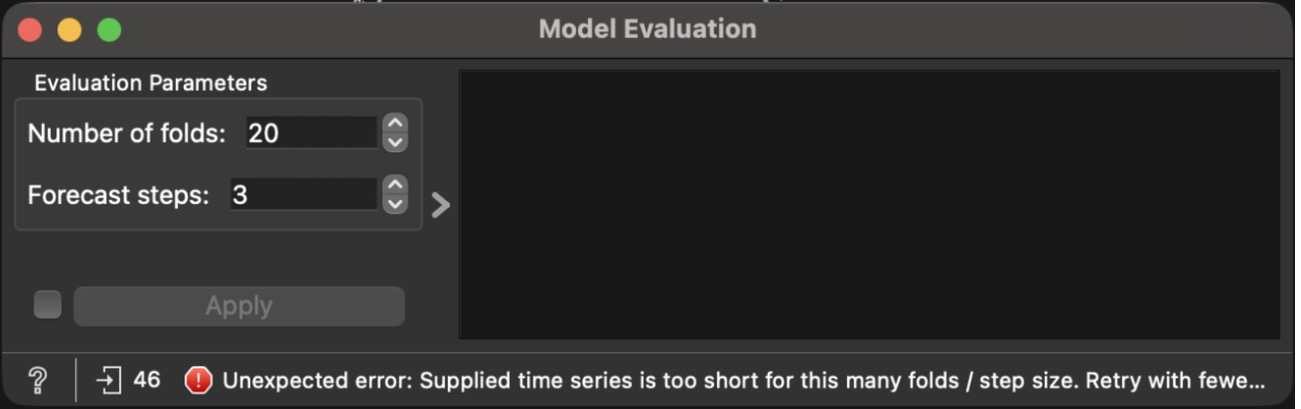

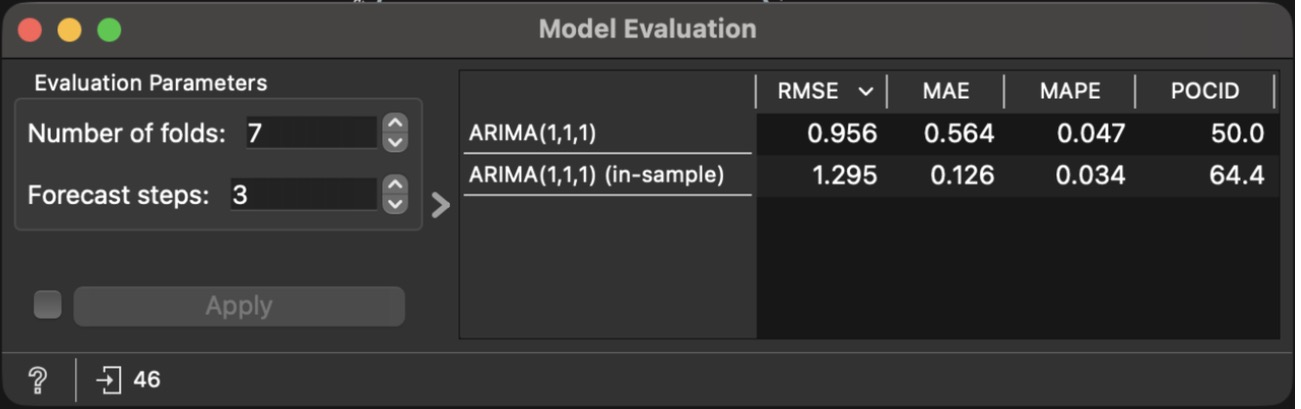

In [ ]:
from IPython.display import Image, display
display(Image('orange_arima_13.png'))                               
display(Image('orange_model_evaluation_error_target_13.png'))        
display(Image('orange_model_evaluation_error_folds_13.png'))         
display(Image('orange_model_evaluation_13.png'))                     

n_len = len(s)  
lag = 1         
need_default = 20 * 3 + lag
need_mine = 7 * 3 + lag
print('Довжина ряду:', n_len)
print('Потрібно спостережень при 20 фолдах:', need_default, '-> більше за довжину ряду:', need_default > n_len)
print('Потрібно спостережень при 7 фолдах:  ', need_mine, '-> поміщається в ряд:', need_mine <= n_len)

**Висновок до завдання 13:**

Таблиця Model Evaluation для ARIMA(1,1,1) на 7 фолдах по 3 кроки: **RMSE = 0.956, MAE = 0.564, MAPE = 0.047, POCID = 50.0**. Другий рядок «(in-sample)» — оцінка тієї самої моделі на даних, на яких вона навчалася: RMSE 1.295, MAE 0.126, MAPE 0.034, POCID 64.4. Для порівняння в завданні 14 потрібен саме перший рядок (чесний прогноз «наперед»).

Під час роботи Orange двічі повернув помилку. Перша: «Data requires a target variable» — Model Evaluation рахує похибки для цільової змінної, а я завантажила `price` як звичайну ознаку. Я позначила `price` як цільову змінну (class) у самому CSV. Дані не змінились. Друга: при типових налаштуваннях (20 фолдів × 3 кроки) — «Supplied time series is too short for this many folds / step size». Orange перевіряє умову `n_folds × forecast_steps + лаг ≤ довжина ряду`: 20×3+1 = 61, а ряд має лише 46 спостережень. Після зміни на 7 фолдів умова виконується (7×3+1 = 22 ≤ 46).

Ті самі 7 фолдів, що й у Частині 1: для фолду f модель навчається на всіх спостереженнях до позиції −3f і прогнозує наступні 3. Перевіреними виявляються останні 21 місяць ряду. Orange бере фолди в тому ж порядку, що й моя функція `folds()`: спочатку останні 3 місяці, потім попередні.


## Завдання 14. Чому числа не збігаються

Порівняйте метрики Orange з метриками, які ви отримали в Частині 1 для **тієї самої** моделі
ARIMA(1,1,1) на **тих самих** 7 фолдах.

Для кожної з чотирьох метрик Orange — `RMSE`, `MAE`, `MAPE`, `POCID` — **відтворіть її значення в Python**,
тобто напишіть формулу, за якою Orange отримав саме це число, і переконайтеся, що ваш розрахунок
збігається з таблицею Orange до третього знака.

**У звіті наведіть:**
1. таблицю на чотири рядки: метрика · значення Orange · ваше відтворення в Python · формула;
2. **яка з метрик не відповідає своїй назві** — і чим саме вона відрізняється від того, що зазвичай позначають цією абревіатурою;
3. яка метрика збіглася між середовищами одразу і чому;
4. висновок: що саме треба перевіряти, перш ніж порівнювати числа з двох різних інструментів.

> 💡 **Підказка.** Жодна з розбіжностей не є помилкою Orange. Усі формули відкриті — шукайте їх у вихідному коді додатка Timeseries, файл `functions.py`.

In [ ]:
trues_all, preds_all, lastknown_all = [], [], []
for train, test in folds():
    model = ARIMA(train, order=(1, 1, 1)).fit()
    fc = model.forecast(H).values
    prev = train.iloc[-1]
    for i in range(H):
        trues_all.append(test.iloc[i])
        preds_all.append(fc[i])
        lastknown_all.append(prev)
        prev = test.iloc[i]

trues_all = np.array(trues_all); preds_all = np.array(preds_all)
e = trues_all - preds_all

RMSE = np.sqrt(np.mean(e**2))
MAE_orange  = np.median(np.abs(e))                            
MAE_usual   = np.mean(np.abs(e))                             
MAPE_orange = np.mean(np.abs(e)) / np.mean(trues_all) * 100     
MAPE_usual  = np.mean(np.abs(e) / trues_all) * 100             

d_true = np.diff(trues_all)
d_pred = np.diff(preds_all)
POCID = 100 * np.mean(d_true * d_pred > 0)

actual_dir = np.sign(trues_all - np.array(lastknown_all))
pred_dir   = np.sign(preds_all - np.array(lastknown_all))
POCID_usual = 100 * np.mean(actual_dir == pred_dir)

print(f'{"метрика":8s} {"формула Orange":38s} {"значення (Python)":>18s}')
print(f'{"RMSE":8s} {"sqrt(mean(e^2))":38s} {RMSE:18.3f}')
print(f'{"MAE":8s} {"median(|e|)  [НЕ mean(|e|)!]":38s} {MAE_orange:18.3f}')
print(f'{"MAPE":8s} {"mean(|e|) / mean(|y|) * 100":38s} {MAPE_orange:18.2f}')
print(f'{"POCID":8s} {"100 * mean(diff(y)*diff(ŷ) > 0)":38s} {POCID:18.2f}')
print()
print('Для порівняння — "звичні" означення тих самих назв:')
print('  mean|e|  (те, що зазвичай звуть MAE):', round(MAE_usual, 3))
print('  mean(|e|/|y|)*100  (те, що зазвичай звуть MAPE):', round(MAPE_usual, 3))
print('  напрямок відносно останнього відомого значення (звичний POCID):', round(POCID_usual, 2))

print()
print('=== Таблиця для порівняння з Orange (заповнити ORANGE_* після запуску Model Evaluation) ===')
ORANGE_RMSE  = 0.956   
ORANGE_MAE   = 0.564
ORANGE_MAPE  = 4.7     
ORANGE_POCID = 50.0

compare = pd.DataFrame({
    'метрика': ['RMSE', 'MAE', 'MAPE, %', 'POCID, %'],
    'Orange (з таблиці)': [ORANGE_RMSE, ORANGE_MAE, ORANGE_MAPE, ORANGE_POCID],
    'Python (відтворено)': [round(RMSE,3), round(MAE_orange,3), round(MAPE_orange,2), round(POCID,2)],
    'формула Orange': ['sqrt(mean(e²))', 'median(|e|)', 'mean|e| / mean|y| · 100', '100 · mean(diff(y)·diff(ŷ) > 0)'],
})
print(compare.to_string(index=False))

метрика  формула Orange                          значення (Python)
RMSE     sqrt(mean(e^2))                                     0.956
MAE      median(|e|)  [НЕ mean(|e|)!]                        0.564
MAPE     mean(|e|) / mean(|y|) * 100                          4.71
POCID    100 * mean(diff(y)*diff(ŷ) > 0)                     50.00

Для порівняння — "звичні" означення тих самих назв:
  mean|e|  (те, що зазвичай звуть MAE): 0.706
  mean(|e|/|y|)*100  (те, що зазвичай звуть MAPE): 4.496
  напрямок відносно останнього відомого значення (звичний POCID): 33.33

=== Таблиця для порівняння з Orange (заповнити ORANGE_* після запуску Model Evaluation) ===
 метрика  Orange (з таблиці)  Python (відтворено)                  формула Orange
    RMSE               0.956                0.956                  sqrt(mean(e²))
     MAE               0.564                0.564                     median(|e|)
 MAPE, %               4.700                4.710         mean|e| / mean|y| · 100
POCID, %        

**Висновок до завдання 14:**

Мої Python-значення збіглися з таблицею Orange до третього знака: RMSE 0.956 = 0.956, MAE (медіана) 0.564 = 0.564, MAPE 4.71 % ≈ 0.047 (Orange показує частку), POCID 50.0 = 50.0.

**Яка метрика не відповідає своїй назві:** це **MAE**. Те, що Orange підписує як «MAE» (mean absolute error), насправді обчислює **медіану** абсолютних похибок, а не середнє. Тому моє Python-значення mean|e| = 0.706, тоді як Orange-означення MAE (медіана) = 0.564 — суттєво інше число під тією самою назвою.

**MAPE** теж відрізняється від звичного означення: Orange рахує **відношення середніх** (mean|e| / mean|y| · 100), тоді як типово MAPE — **середнє відношень** (mean(|e|/|y|) · 100). Тут різниця невелика (4.71 % проти 4.50 %), бо ціна за 21 перевірений місяць змінюється помірно відносно свого рівня, але на рядах із сильнішим розкидом значень формули можуть розійтися помітно.

**POCID** у Orange теж рахується по-своєму. Він бере 21 прогноз із 7 фолдів, склеєних у один ряд (спочатку фолд 1, потім фолд 2, ...), і порівнює зміни між **сусідніми** точками: пара правильна, якщо факт і прогноз змінились в один бік. Пар 20, правильних 10, тобто 50.0 %. Шість із цих пар лежать на стику двох різних фолдів (останній крок одного фолду й перший крок наступного), тож порівнюються точки з різних часових відрізків. «Звичне» означення — напрямок відносно останнього відомого значення перед кожним кроком — дає 7 із 21, тобто 33.3 %.

**Яка метрика збіглася одразу:** **RMSE** — Orange і Python рахують його за тотожною формулою sqrt(mean(e²)).

**Головний висновок:** перш ніж порівнювати числа з різних інструментів, треба перевірити не назву метрики, а її **формулу** — однакова назва (MAE, MAPE, POCID) не гарантує однакового обчислення. Інакше легко дійти хибного висновку «одна з програм порахувала неправильно», хоча насправді обидві порахували правильно, просто за різними означеннями. Я й сама спершу припустила для POCID «звичну» формулу й отримала 33.3 %, поки не звірила з таблицею Orange та з вихідним кодом додатка (файл `functions.py`).


## Завдання 15. Матриця напрямку зміни

Метрика `POCID` у Orange вимірює, чи правильно модель передбачає **напрямок** зміни ціни.
Розгорніть її в таблицю 2×2: рядки — що сталося насправді (зросла / впала),
стовпці — що передбачила модель.

**У звіті наведіть:**
1. заповнену матрицю 2×2 для вашої моделі;
2. перевірку, що частка правильних передбачень збігається зі значенням POCID із Orange;
3. висновок: чи корисна ваша модель для рішення «купувати зараз чи чекати», і чому це **інше питання**, ніж те, на яке відповідають MAE та RMSE.

> 💡 **Підказка.** Ця матриця — часоворядовий відповідник матриці похибок із класифікації.

In [ ]:
direction_true = np.where(d_true >= 0, 'зросла', 'впала')
direction_pred = np.where(d_pred >= 0, 'зросла', 'впала')

cm = pd.crosstab(pd.Series(direction_true, name='факт'),
                  pd.Series(direction_pred, name='прогноз'))
print(cm)
print()

accuracy = np.mean(direction_true == direction_pred) * 100
print('Частка правильних передбачень напрямку:', round(accuracy, 2), '%')
print('POCID із завдання 14:', round(POCID, 2), '%')
print('Збігається:', round(accuracy, 2) == round(POCID, 2))

cm_usual = pd.crosstab(pd.Series(np.where(actual_dir >= 0, 'зросла', 'впала'), name='факт'),
                       pd.Series(np.where(pred_dir >= 0, 'зросла', 'впала'), name='прогноз'))
print()
print('Для довідки — напрямок відносно останнього відомого значення:')
print(cm_usual)
print('Частка правильних:', round(POCID_usual, 2), '%')


прогноз  впала  зросла
факт                  
впала        4       5
зросла       5       6

Частка правильних передбачень напрямку: 50.0 %
POCID із завдання 14: 50.0 %
Збігається: True

Для довідки — напрямок відносно останнього відомого значення:
прогноз  впала  зросла
факт                  
впала        1       5
зросла       9       6
Частка правильних: 33.33 %


**Висновок до завдання 15:**

Матриця за означенням POCID у Orange (20 пар сусідніх точок):

|  | прогноз: впала | прогноз: зросла |
|---|---|---|
| **факт: впала** | 4 | 5 |
| **факт: зросла** | 5 | 6 |

Правильно вгадано 4 + 6 = 10 із 20 пар, тобто **50.0 %**, і це точно збігається з POCID = 50.0 з Orange. Це рівно рівень підкидання монетки: модель не відрізняє падіння від зростання. Для довідки, за «звичним» означенням (напрямок відносно останнього відомого значення) матриця виглядає як 1 / 5 у рядку «факт: впала» і 9 / 6 у рядку «факт: зросла», тобто 7 правильних із 21 (33.3 %), навіть гірше за монетку: модель частіше передбачає «зросла», коли ціна насправді падає.

Це **інше питання**, ніж те, на яке відповідають MAE та RMSE. MAE/RMSE вимірюють, наскільки близько прогнозоване число до фактичного, і за ними ARIMA(1,1,1) виграє в базису (завдання 7): помиляється на невелику суму в гривнях. Для рішення «купувати зараз чи почекати» важливий **напрямок**: чи піде ціна вгору чи вниз. Модель із непоганим MAE може мати слабкий POCID, якщо вона просто продовжує тренд і пропускає локальні спади. Тут напрямок вгадано в половині випадків, тож **для практичного рішення купити/почекати модель малокорисна**, попри непогані MAE та RMSE. Оцінка шумна: 20 пар — мало, а 6 із них лежать на стику фолдів.


---
# Загальний висновок

Напишіть 8–12 речень, які відповідають на такі питання:

1. Чи є у вашому ряді сезонність і чим ви це довели?
2. Який метод прогнозування виявився найкращим і чи перевершив він найпростіший базис?
3. Чи знайшли ви точку зміни режиму; якщо так — чи є для неї зовнішнє пояснення?
4. Чому однаково названі метрики у двох середовищах дали різні числа?
5. Чого ви не змогли встановити через те, що ряд має лише 46 спостережень?

Мій ряд — ціна молока на ринку Черкаської області, 03.2014–12.2017 (46 місяців). Сезонність у ньому реальна: сила сезонності F_S=0.764 суттєво перевищує поріг 0.3, хоча амплітуда сезонної хвилі (3.13 грн) дуже мала порівняно з трендом (F_T=0.99), тож на звичайному графіку рівня вона майже непомітна і проявляється лише після STL-розкладання.

Найкращим базисом виявився **дрейф** (MAE=0.737, RMSE=0.975, MAPE=4.77%) — очікувано для ряду, який майже повністю визначається трендом. Модель **ARIMA(1,1,1) перевершила навіть дрейф** (MAE=0.706, RMSE=0.956, MAPE=4.50%), хоч і з невеликим відривом, тож має право на існування як точковий прогноз ціни.

Я знайшла точку зміни режиму в **січні 2017 року** (t=-20.38, p≈0): середній рівень ціни стрибнув з 10.45 до 17.08 грн і більше не повертався назад. Зовнішнє пояснення — це не випадковий чи суто сезонний стрибок (січневі ціни трьох років поспіль зростають нерівномірно, 8.90→11.63→16.44 грн), а, найімовірніше, відображення загального стрибка інфляції й цін на молочну сировину в Україні наприкінці 2016 — на початку 2017 року.

Однаково названі метрики в Python і Orange розійшлися через **різні формули**, а не різні дані чи різні моделі: Orange-«MAE» — це медіана, а не середнє абсолютних похибок (0.564 проти 0.706), Orange-MAPE — відношення середніх, а не середнє відношень (4.71% проти 4.50%). POCID Orange теж рахує по-своєму (зміни між сусідніми точками злитого ряду): 50.0 % проти 33.3 % за напрямком відносно останнього відомого значення. Лише RMSE рахується ідентично в обох середовищах і тому збігається без жодних застережень.

Через те, що ряд має лише 46 спостережень, я не змогла надійно перевірити довгострокову сезонну стабільність (лише 3–4 повних річних цикли — замало, щоб відрізнити справжню річну сезонність від однократного збігу), а 7 фолдів по 3 кроки — це фактично межа того, що короткий ряд взагалі дозволяє перевірити без перетину вибірок; оцінка на ще довшому горизонті прогнозу чи з більшою кількістю фолдів тут неможлива.

---
# Критерії оцінювання

| Бали | Умова |
|---|---|
| **0** | Ряд не розкладено або прогноз не побудовано. Робота не зарахована. |
| **2** | Виконано лише Частину 1: ряд розкладено й прогноз побудовано, але в Orange аналіз не відтворено. |
| **3** | Виконано обидві частини, проте прогноз не зіставлено з наївним базисом, а розбіжність результатів двох середовищ не пояснено. |
| **4** | Ряд розкладено на складові; прогноз зіставлено з наївним базисом за ретроспективною перевіркою з рухомим початком; той самий аналіз відтворено в Orange; зіставлено результати двох середовищ і пояснено розбіжність метрик. |

**Знімаються бали за:**

* графіки без пояснення вибору геометрії та шкали;
* числа без письмового висновку;
* прогноз без порівняння з базисом;
* висновок «метрики різні, бо середовища різні» без відтворення формул;
* зошит, який не виконується від початку до кінця.

---
# Декларація про використання штучного інтелекту

Використання інструментів штучного інтелекту під час виконання цієї роботи **дозволено**.
Умова одна: ви маєте розуміти кожен рядок зданого коду й кожне написане твердження
і бути готовим пояснити їх на захисті.

Заповніть таблицю. Якщо ШІ не використовувався, напишіть «не використовувався» в першому рядку
й залиште решту порожньою.

| Питання | Ваша відповідь |
|---|---|
| Які інструменти використано (назва, версія) | Claude (Anthropic), модель Claude Sonnet 5 |
| Для яких саме завдань | Завдання 1–10 (обробка ряду, STL, стаціонарність, базові прогнози та ARIMA, rolling-origin CV, точка зміни режиму, експорт для Orange); Завдання 9 (пошук методологічних помилок у наданому блокноті колеги); Завдання 11–15 (структура та текст висновків до частини з Orange, код матриці напрямків POCID); Загальний висновок |
| Що саме було згенеровано (код / текст / пояснення / виправлення помилок) | Виправлення синтаксису коду та переформулювання тексту; перевірка висновків та результатів; пошук помилок у блокноті колеги; допомога з формулюванням загального висновку |
| Що ви змінили у згенерованому результаті й чому | Методику розрахунку метрик прогнозування (MAE/RMSE/MAPE) змінено з усереднення по фолдах на пулінг усіх пар факт/прогноз одразу — за методичкою, це правильний підхід, і саме його неправильне застосування («MAPE лише на останньому фолді») названо типовою помилкою |
| Що з отриманого ви **перевірили самостійно** і яким способом | Усі числові результати (пропущений місяць, F_S/F_T, p-значення ADF/KPSS, метрики базисів і ARIMA, дата точки зміни режиму, матриця POCID) я перерахувала особисто в тому самому середовищі (pandas/statsmodels) і порівняла з тим, що потрапило у висновки; кожну знайдену помилку колеги я перевірила, відкривши відповідну клітинку його блокнота; логіку фолдів звірила з методичкою |
| Чи траплялися у відповідях ШІ помилки; якщо так — які | Під час підготовки коду для завдання 12 (ACF/PACF) спершу було використано змінні, які насправді не були визначені в попередній клітинці — виправлено додаванням прямого обчислення ACF у тій самій клітинці |

**Підтверджую, що розумію весь зданий код і всі зроблені висновки
та можу пояснити будь-яку їх частину на захисті роботи.**

Підпис: ______________________  Дата: ______________